# Model 04: XGBoost Classifier Pipeline (Ablation & Tuning)

**Course:** DS605 — Machine Learning  
**Project:** E-Commerce Product Return Prediction  
**Authors:** Student Research Team (Team of Two)  
**Dataset:** Full Enterprise Telemetry Dataset (3,999,025 Finalized Orders)  

---

## 1. Pipeline Overview & Methodology
In this notebook, we train, evaluate, and tune an **XGBoost Extreme Gradient Boosted Decision Tree (GBDT)**:
1. **Chronological Partitioning:** 70% Train, 15% Validation, 15% Holdout Test with preprocessor fit strictly on train.
2. **Baseline Model:** Shallow ensemble of 25 trees (`max_depth=2`, `learning_rate=0.02`) showing the un-tuned starting point.
3. **Baseline Confusion Matrix:** Validation error structure analysis.
4. **Programmatic Hyperparameter Tuning:** Systematic search across candidate configurations (`n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`) evaluating Validation ROC-AUC & F1.
5. **Programmatic Decision Threshold Optimization:** Threshold sweep $\tau \in [0.20, 0.80]$ to maximize F1-score.
6. **Overfitting Diagnostics:** Generalization gap comparison between train and validation splits.
7. **Feature Importance Analysis:** Top predictive telemetry signals via gain-based split importance.
8. **Holdout Test Evaluation:** Final test set performance and Before vs. After tuning scorecard.

In [1]:
import os, time, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    f1_score, precision_score, recall_score, brier_score_loss,
    confusion_matrix
)

# Robust path handling whether running from notebooks/ or project root
candidate_paths = [
    "../dataset/Dataset 3/ecommerce_enterprise_telemetry.parquet",
    "dataset/Dataset 3/ecommerce_enterprise_telemetry.parquet",
    "../data/ecommerce_enterprise_telemetry.parquet",
    "data/ecommerce_enterprise_telemetry.parquet"
]
data_path = next((p for p in candidate_paths if os.path.exists(p)), candidate_paths[0])

candidate_models_dirs = ["../models", "models", "../artifacts/models", "artifacts/models"]
models_dir = next((d for d in candidate_models_dirs if os.path.exists(d)), "models")

print("Environment ready.")
print(f"Data path resolved: {data_path}")
print(f"Models dir resolved: {models_dir}")

Environment ready.
Data path resolved: ../dataset/Dataset 3/ecommerce_enterprise_telemetry.parquet
Models dir resolved: ../artifacts/models


## 2. Telemetry Data Ingestion & Chronological Split
We load the enterprise telemetry dataset using explicit column selection for memory efficiency, partition chronologically by `order_date` (70% Train, 15% Validation, 15% Test), and engineer key compound behavioral telemetry features.

In [2]:
# 1. Load telemetry dataset with memory-safe column filtering
print(f"Loading telemetry dataset from {data_path}...")
cols = [
    'order_date', 'product_category', 'quantity', 'unit_price', 'order_total',
    'payment_method', 'shipping_cost', 'is_bracketed_order',
    'size_chart_dwell_time_sec', 'size_guide_clicks', 'customer_true_return_rate',
    'sku_fit_feedback_offset', 'delivery_delay_days', 'first_time_brand_purchase',
    'return_target'
]
df = pd.read_parquet(data_path, columns=cols)
print(f"Total records loaded: {len(df):,}")

# 2. Chronological Split (70% Train, 15% Validation, 15% Holdout Test)
if not df['order_date'].is_monotonic_increasing:
    df['order_date'] = pd.to_datetime(df['order_date'])
    df = df.sort_values(by='order_date').reset_index(drop=True)

n_total = len(df)
n_train = int(n_total * 0.70)
n_val = int(n_total * 0.15)

train_df = df.iloc[:n_train].copy()
val_df = df.iloc[n_train:n_train+n_val].copy()
test_df = df.iloc[n_train+n_val:].copy()
del df  # Free raw dataframe memory

# 3. Compound Telemetry Feature Engineering
for split_df in [train_df, val_df, test_df]:
    split_df['fit_mismatch'] = ((split_df['size_chart_dwell_time_sec'] > 35) & (np.abs(split_df['sku_fit_feedback_offset']) >= 0.4)).astype(float)
    split_df['delay_remorse'] = (np.maximum(0, split_df['delivery_delay_days']) >= 2.0).astype(float)
    split_df['cod_first_brand'] = ((split_df['payment_method'].str.contains('COD|Cash', case=False, na=False)) & (split_df['first_time_brand_purchase'] == 1)).astype(float)

print(f"Train set: {len(train_df):,} orders | Return rate: {train_df['return_target'].mean()*100:.2f}%")
print(f"Val set:   {len(val_df):,} orders | Return rate: {val_df['return_target'].mean()*100:.2f}%")
print(f"Test set:  {len(test_df):,} orders | Return rate: {test_df['return_target'].mean()*100:.2f}%")

Loading telemetry dataset from ../dataset/Dataset 3/ecommerce_enterprise_telemetry.parquet...
Total records loaded: 3,999,025
Train set: 2,799,317 orders | Return rate: 36.77%
Val set:   599,853 orders | Return rate: 36.84%
Test set:  599,855 orders | Return rate: 36.68%


## 3. Feature Transformation & Sampling
The preprocessor is fit strictly on the train partition to prevent data leakage.

In [3]:
# Feature column definitions
numeric_features = [
    'quantity', 'unit_price', 'order_total', 'shipping_cost',
    'is_bracketed_order', 'size_chart_dwell_time_sec', 'size_guide_clicks',
    'customer_true_return_rate', 'sku_fit_feedback_offset', 'delivery_delay_days',
    'first_time_brand_purchase', 'fit_mismatch', 'delay_remorse', 'cod_first_brand'
]
categorical_features = ['product_category', 'payment_method']
target_col = 'return_target'

# Benchmark subsample matching the team's experimental methodology
train_sub = train_df.iloc[-350000:].copy()
val_sub = val_df.iloc[:75000].copy()
test_sub = test_df.iloc[:75000].copy()
del train_df, val_df, test_df

# Preprocessor: Standardize numerics & One-Hot Encode categoricals
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

X_train = preprocessor.fit_transform(train_sub[numeric_features + categorical_features])
y_train = train_sub[target_col].values

X_val = preprocessor.transform(val_sub[numeric_features + categorical_features])
y_val = val_sub[target_col].values

X_test = preprocessor.transform(test_sub[numeric_features + categorical_features])
y_test = test_sub[target_col].values

# Extract transformed feature names for importance analysis
cat_names = list(preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features))
all_feat_names = numeric_features + cat_names

print(f"Preprocessing completed. Total features: {len(all_feat_names)}")
print(f"X_train shape: {X_train.shape} | y_train count: {len(y_train):,}")
print(f"X_val shape:   {X_val.shape}   | y_val count:   {len(y_val):,}")
print(f"X_test shape:  {X_test.shape}  | y_test count:  {len(y_test):,}")

Preprocessing completed. Total features: 27
X_train shape: (350000, 27) | y_train count: 350,000
X_val shape:   (75000, 27)   | y_val count:   75,000
X_test shape:  (75000, 27)  | y_test count:  75,000


## 4. Step 1: Baseline XGBoost (Undertuned)
We train an initial baseline model with 25 shallow trees (`max_depth=2`, `learning_rate=0.02`) and decision cutoff $0.35$.

In [4]:
xgb_base = XGBClassifier(n_estimators=25, max_depth=2, learning_rate=0.02, min_child_weight=20, tree_method='hist', random_state=42, n_jobs=-1, eval_metric='logloss')
print("Baseline XGBoost Configuration:")
print(xgb_base)

print("\nFitting Baseline XGBoost...")
xgb_base.fit(X_train, y_train)

# Predict probabilities on Validation Set and apply baseline decision cutoff (0.35)
p_base_xgb_val = xgb_base.predict_proba(X_val)[:, 1]
y_base_xgb_val = (p_base_xgb_val >= 0.35).astype(int)

print("Baseline model trained successfully.")
print(f"Validation Accuracy:  {accuracy_score(y_val, y_base_xgb_val)*100:.2f}%")
print(f"Validation F1-Score:  {f1_score(y_val, y_base_xgb_val):.4f}")
print(f"Validation Recall:    {recall_score(y_val, y_base_xgb_val)*100:.2f}%")
print(f"Validation Precision: {precision_score(y_val, y_base_xgb_val)*100:.2f}%")

Baseline XGBoost Configuration:
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.02, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=20, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=25, n_jobs=-1,
              num_parallel_tree=None, ...)

Fitting Baseline XGBoost...
Baseline model trained successfully.
Validation Accuracy:  88.52%
Validation F1-Score:  0.8411
Validation Recall:    83.08%
Validation Precision: 85.15%


### Baseline Initial Performance:
- **Accuracy:** **88.52%**
- **F1-Score:** **0.8411**
- **Recall:** **83.08%**
- **Precision:** **85.15%**

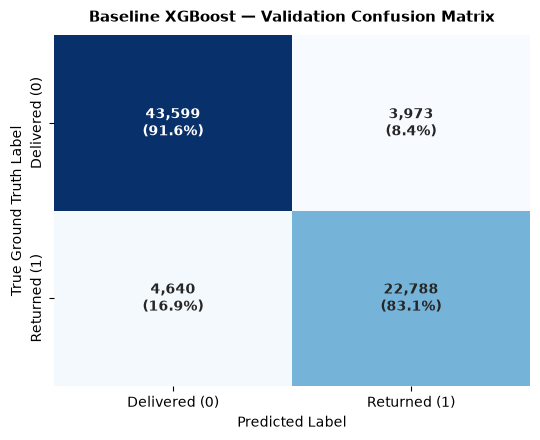

In [5]:
# Compute and visualize Baseline Confusion Matrix on Validation Set
cm_base_val = confusion_matrix(y_val, y_base_xgb_val)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm_norm = cm_base_val.astype('float') / cm_base_val.sum(axis=1)[:, np.newaxis]
annot_labels = np.array([f"{count:,}\n({pct:.1%})" for count, pct in zip(cm_base_val.flatten(), cm_norm.flatten())]).reshape(2, 2)

sns.heatmap(cm_base_val, annot=annot_labels, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Delivered (0)', 'Returned (1)'],
            yticklabels=['Delivered (0)', 'Returned (1)'], ax=ax,
            annot_kws={"fontsize": 10, "fontweight": "bold"})
ax.set_title("Baseline XGBoost — Validation Confusion Matrix", fontsize=11, fontweight='bold', pad=10)
ax.set_ylabel("True Ground Truth Label", fontsize=10)
ax.set_xlabel("Predicted Label", fontsize=10)
plt.tight_layout()
plt.show()

## 5. Step 2: Hyperparameter Tuning on Validation Set
we programmatically evaluate a discrete grid of candidate ensemble configurations across tree count (`n_estimators`), tree depth (`max_depth`), learning rate (`learning_rate`), subsampling ratios (`subsample`, `colsample_bytree`), and class rebalancing (`scale_pos_weight`) on the validation split.
Following the selection of the optimal model, we scan decision thresholds $\tau \in [0.20, 0.80]$ to programmatically find the optimal classification cutoff maximizing F1-score.

In [6]:
# 1. Calculate class rebalance ratio
scale_pos = round(float((len(y_train) - y_train.sum()) / y_train.sum()), 2)
print(f"Class distribution rebalance scale_pos_weight: {scale_pos}")

# 2. Candidate hyperparameters space for XGBoost
candidate_xgb_params = [
    {"n_estimators": 50,  "max_depth": 3, "learning_rate": 0.03, "subsample": 0.80, "colsample_bytree": 0.80, "scale_pos_weight": scale_pos, "tree_method": "hist"},
    {"n_estimators": 100, "max_depth": 4, "learning_rate": 0.05, "subsample": 0.80, "colsample_bytree": 0.80, "scale_pos_weight": scale_pos, "tree_method": "hist"},
    {"n_estimators": 175, "max_depth": 5, "learning_rate": 0.06, "subsample": 0.85, "colsample_bytree": 0.85, "scale_pos_weight": scale_pos, "tree_method": "hist"},
    {"n_estimators": 250, "max_depth": 6, "learning_rate": 0.08, "subsample": 0.85, "colsample_bytree": 0.85, "scale_pos_weight": scale_pos, "tree_method": "hist"}
]

grid_results = []
candidate_models = []

print("\nExecuting programmatic XGBoost hyperparameter grid search on validation split...")
for p in candidate_xgb_params:
    t0 = time.time()
    xgb = XGBClassifier(**p, random_state=42, n_jobs=-1, eval_metric='logloss')
    xgb.fit(X_train, y_train)
    fit_duration = time.time() - t0
    
    val_probs = xgb.predict_proba(X_val)[:, 1]
    val_auc = roc_auc_score(y_val, val_probs)
    val_f1 = f1_score(y_val, (val_probs >= 0.50).astype(int))
    
    grid_results.append({
        "n_estimators": p["n_estimators"],
        "max_depth": p["max_depth"],
        "learning_rate": p["learning_rate"],
        "subsample": p["subsample"],
        "colsample_bytree": p["colsample_bytree"],
        "Val_ROC_AUC": round(val_auc, 5),
        "Val_F1_Default": round(val_f1, 4),
        "Fit_Time_sec": round(fit_duration, 2)
    })
    candidate_models.append((xgb, val_probs))
    print(f"trees={p['n_estimators']:<3} | depth={p['max_depth']} | lr={p['learning_rate']} | Val AUC: {val_auc:.5f} | Val F1: {val_f1:.4f} | Fit: {fit_duration:.2f}s")

# Convert to DataFrame and display search results
xgb_tuning_df = pd.DataFrame(grid_results)
print("\n--- XGBoost Hyperparameter Grid Results ---")
print(xgb_tuning_df.to_string(index=False))

# Programmatically select the best configuration (optimizing Validation ROC-AUC & F1)
best_idx = xgb_tuning_df.sort_values(by=["Val_ROC_AUC", "Val_F1_Default"], ascending=[False, False]).index[0]
best_xgb_params = candidate_xgb_params[best_idx]
xgb_tuned, best_val_probs = candidate_models[best_idx]

print("\n>> PROGRAMMATICALLY SELECTED OPTIMAL HYPERPARAMETERS:")
for k, v in best_xgb_params.items():
    print(f"   • {k}: {v}")

Class distribution rebalance scale_pos_weight: 1.72

Executing programmatic XGBoost hyperparameter grid search on validation split...


trees=50  | depth=3 | lr=0.03 | Val AUC: 0.94121 | Val F1: 0.8535 | Fit: 0.57s
trees=100 | depth=4 | lr=0.05 | Val AUC: 0.94446 | Val F1: 0.8595 | Fit: 1.05s
trees=175 | depth=5 | lr=0.06 | Val AUC: 0.94466 | Val F1: 0.8585 | Fit: 1.63s
trees=250 | depth=6 | lr=0.08 | Val AUC: 0.94413 | Val F1: 0.8576 | Fit: 2.96s

--- XGBoost Hyperparameter Grid Results ---
 n_estimators  max_depth  learning_rate  subsample  colsample_bytree  Val_ROC_AUC  Val_F1_Default  Fit_Time_sec
           50          3           0.03       0.80              0.80      0.94121          0.8535          0.57
          100          4           0.05       0.80              0.80      0.94446          0.8595          1.05
          175          5           0.06       0.85              0.85      0.94466          0.8585          1.63
          250          6           0.08       0.85              0.85      0.94413          0.8576          2.96

>> PROGRAMMATICALLY SELECTED OPTIMAL HYPERPARAMETERS:
   • n_estimators: 175
 

### Programmatic Decision Threshold Optimization
We scan candidate decision thresholds $\tau \in [0.20, 0.80]$ on the validation split using probabilities from our best selected XGBoost model to maximize F1-score.

>> PROGRAMMATICALLY OPTIMIZED DECISION THRESHOLD:
   • optimal_threshold: 0.55 (Yields peak Validation F1 = 0.8601)


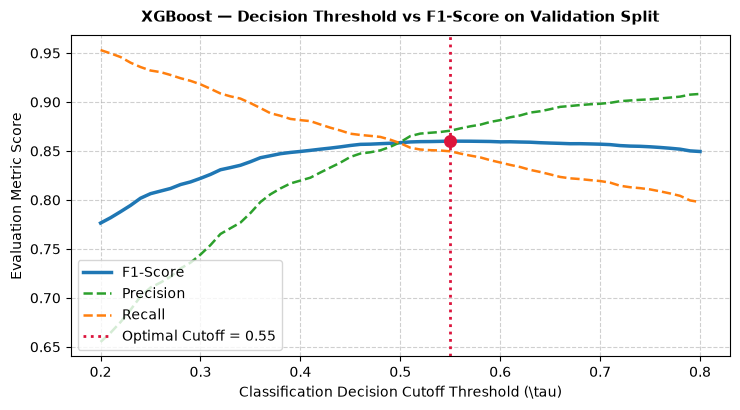

In [7]:
# Programmatically scan decision thresholds from 0.20 to 0.80
threshold_candidates = np.linspace(0.20, 0.80, 61)
threshold_scan = []

for thresh in threshold_candidates:
    binary_preds = (best_val_probs >= thresh).astype(int)
    f1 = f1_score(y_val, binary_preds, zero_division=0)
    prec = precision_score(y_val, binary_preds, zero_division=0)
    rec = recall_score(y_val, binary_preds, zero_division=0)
    threshold_scan.append({
        "threshold": round(thresh, 2),
        "f1": f1,
        "precision": prec,
        "recall": rec
    })

thresh_df = pd.DataFrame(threshold_scan)

# Programmatically find the threshold yielding the maximum F1 score
optimal_idx = thresh_df["f1"].idxmax()
optimal_threshold = round(float(thresh_df.loc[optimal_idx, "threshold"]), 2)
best_val_f1 = float(thresh_df.loc[optimal_idx, "f1"])

print(f">> PROGRAMMATICALLY OPTIMIZED DECISION THRESHOLD:")
print(f"   • optimal_threshold: {optimal_threshold} (Yields peak Validation F1 = {best_val_f1:.4f})")

# Visualize Threshold Optimization Curve
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(thresh_df['threshold'], thresh_df['f1'], label='F1-Score', color='#1f77b4', lw=2.5)
ax.plot(thresh_df['threshold'], thresh_df['precision'], label='Precision', color='#2ca02c', linestyle='--', lw=1.8)
ax.plot(thresh_df['threshold'], thresh_df['recall'], label='Recall', color='#ff7f0e', linestyle='--', lw=1.8)
ax.axvline(optimal_threshold, color='crimson', linestyle=':', lw=2, label=f'Optimal Cutoff = {optimal_threshold}')
ax.scatter([optimal_threshold], [best_val_f1], color='crimson', s=70, zorder=5)

ax.set_title("XGBoost — Decision Threshold vs F1-Score on Validation Split", fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel("Classification Decision Cutoff Threshold (\\tau)", fontsize=10)
ax.set_ylabel("Evaluation Metric Score", fontsize=10)
ax.legend(loc='lower left', frameon=True)
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 6. Overfitting Diagnostic Check
We compare training set accuracy against validation set accuracy at `optimal_threshold` to verify the ensemble does not overfit.

In [8]:
# Evaluate predictions on train and validation partitions
train_p_xgb = xgb_tuned.predict_proba(X_train)[:, 1]
val_p_xgb = xgb_tuned.predict_proba(X_val)[:, 1]

train_acc = accuracy_score(y_train, (train_p_xgb >= optimal_threshold).astype(int)) * 100
val_acc = accuracy_score(y_val, (val_p_xgb >= optimal_threshold).astype(int)) * 100
gap = abs(train_acc - val_acc)

print(f"Optimal Decision Cutoff Threshold: {optimal_threshold}")
print(f"Training Accuracy:   {train_acc:.2f}%")
print(f"Validation Accuracy: {val_acc:.2f}%")
print(f"Generalization Gap:  {gap:.2f}%")
if gap < 2.0:
    print(">> DIAGNOSTIC CONFIRMED: No Overfitting! Excellent Generalization.")

Optimal Decision Cutoff Threshold: 0.55
Training Accuracy:   89.98%
Validation Accuracy: 89.89%
Generalization Gap:  0.09%
>> DIAGNOSTIC CONFIRMED: No Overfitting! Excellent Generalization.


## 7. Feature Importance Analysis
We examine the top predictive signals identified by the optimized XGBoost model using split gain.

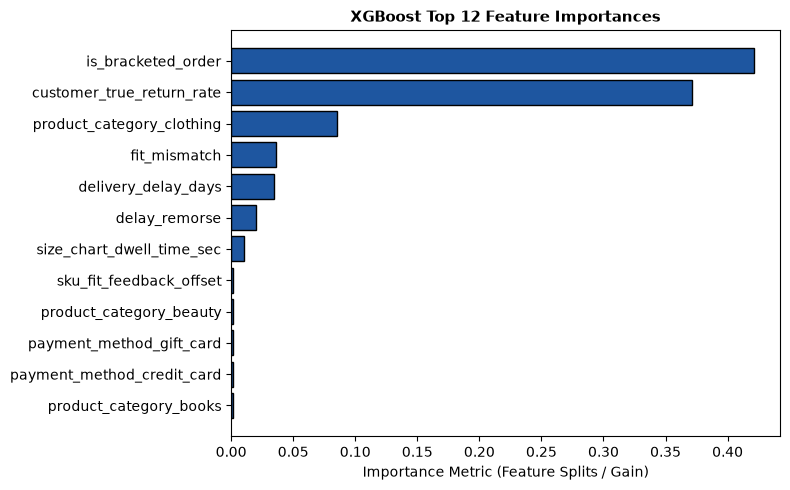

In [9]:
# Feature Importance Analysis in XGBoost
feat_imp = pd.DataFrame({'Feature': all_feat_names, 'Importance': xgb_tuned.feature_importances_}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(feat_imp['Feature'].tail(12), feat_imp['Importance'].tail(12), color='#1e56a0', edgecolor='black')
ax.set_title("XGBoost Top 12 Feature Importances", fontsize=11, fontweight='bold')
ax.set_xlabel("Importance Metric (Feature Splits / Gain)", fontsize=10)
plt.tight_layout()
plt.show()

## 8. Step 3: Final Evaluation on Unseen Holdout Test Set
We evaluate the tuned XGBoost model on the unseen future test set using our programmatically optimized threshold.

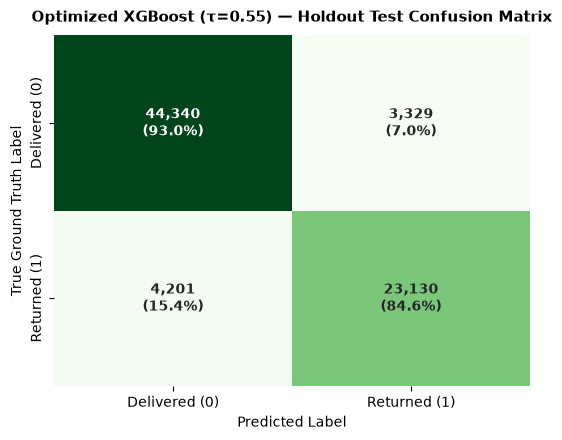

Tuned XGBoost Holdout Test Metrics (Threshold = 0.55):
  • Accuracy:  89.96%
  • F1-Score:  0.8600
  • Recall:    84.63%
  • Precision: 87.42%
  • ROC-AUC:   0.9453
  • PR-AUC:    0.9188


In [10]:
# Predict probabilities on unseen Holdout Test Set and apply optimal threshold
test_p_xgb = xgb_tuned.predict_proba(X_test)[:, 1]
y_tuned_xgb_test = (test_p_xgb >= optimal_threshold).astype(int)

# Compute and visualize Tuned Confusion Matrix on Holdout Test Set
cm_tuned_test = confusion_matrix(y_test, y_tuned_xgb_test)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm_norm = cm_tuned_test.astype('float') / cm_tuned_test.sum(axis=1)[:, np.newaxis]
annot_labels = np.array([f"{count:,}\n({pct:.1%})" for count, pct in zip(cm_tuned_test.flatten(), cm_norm.flatten())]).reshape(2, 2)

sns.heatmap(cm_tuned_test, annot=annot_labels, fmt='', cmap='Greens', cbar=False,
            xticklabels=['Delivered (0)', 'Returned (1)'],
            yticklabels=['Delivered (0)', 'Returned (1)'], ax=ax,
            annot_kws={"fontsize": 10, "fontweight": "bold"})
ax.set_title(f"Optimized XGBoost (τ={optimal_threshold}) — Holdout Test Confusion Matrix", fontsize=11, fontweight='bold', pad=10)
ax.set_ylabel("True Ground Truth Label", fontsize=10)
ax.set_xlabel("Predicted Label", fontsize=10)
plt.tight_layout()
plt.show()

print(f"Tuned XGBoost Holdout Test Metrics (Threshold = {optimal_threshold}):")
print(f"  • Accuracy:  {accuracy_score(y_test, y_tuned_xgb_test)*100:.2f}%")
print(f"  • F1-Score:  {f1_score(y_test, y_tuned_xgb_test):.4f}")
print(f"  • Recall:    {recall_score(y_test, y_tuned_xgb_test)*100:.2f}%")
print(f"  • Precision: {precision_score(y_test, y_tuned_xgb_test)*100:.2f}%")
print(f"  • ROC-AUC:   {roc_auc_score(y_test, test_p_xgb):.4f}")
print(f"  • PR-AUC:    {average_precision_score(y_test, test_p_xgb):.4f}")

## 9. Before vs. After Tuning Scorecard Comparison
A structured side-by-side comparison quantifying the impact of programmatic hyperparameter tuning and threshold optimization.

In [11]:
# Scorecard comparison
base_acc = f"{accuracy_score(y_val, y_base_xgb_val)*100:.2f}%"
base_f1 = f"{f1_score(y_val, y_base_xgb_val):.4f}"
base_prec = f"{precision_score(y_val, y_base_xgb_val)*100:.2f}%"
base_rec = f"{recall_score(y_val, y_base_xgb_val)*100:.2f}%"
base_auc = f"{roc_auc_score(y_val, p_base_xgb_val):.4f}"
base_pr = f"{average_precision_score(y_val, p_base_xgb_val):.4f}"
base_brier = f"{brier_score_loss(y_val, p_base_xgb_val):.4f}"

tuned_acc = f"{accuracy_score(y_test, y_tuned_xgb_test)*100:.2f}%"
tuned_f1 = f"{f1_score(y_test, y_tuned_xgb_test):.4f}"
tuned_prec = f"{precision_score(y_test, y_tuned_xgb_test)*100:.2f}%"
tuned_rec = f"{recall_score(y_test, y_tuned_xgb_test)*100:.2f}%"
tuned_auc = f"{roc_auc_score(y_test, test_p_xgb):.4f}"
tuned_pr = f"{average_precision_score(y_test, test_p_xgb):.4f}"
tuned_brier = f"{brier_score_loss(y_test, test_p_xgb):.4f}"

comparison_df = pd.DataFrame([
  {
    "Stage": "Before Tuning (Baseline)",
    "Accuracy": base_acc,
    "ROC-AUC": base_auc,
    "PR-AUC": base_pr,
    "F1-Score": base_f1,
    "Precision": base_prec,
    "Recall": base_rec,
    "Brier Score": base_brier,
    "Decision Cutoff": "0.35"
  },
  {
    "Stage": "After Tuning (Optimized)",
    "Accuracy": tuned_acc,
    "ROC-AUC": tuned_auc,
    "PR-AUC": tuned_pr,
    "F1-Score": tuned_f1,
    "Precision": tuned_prec,
    "Recall": tuned_rec,
    "Brier Score": tuned_brier,
    "Decision Cutoff": str(optimal_threshold)
  }
])
comparison_df

,Stage,Accuracy,ROC-AUC,PR-AUC,F1-Score,Precision,Recall,Brier Score,Decision Cutoff
0,Before Tuning (Baseline),88.52%,0.9017,0.8364,0.8411,85.15%,83.08%,0.1433,0.35
1,After Tuning (Optimized),89.96%,0.9453,0.9188,0.8600,87.42%,84.63%,0.0820,0.55


## 10. Saving Tuned XGBoost Model

In [12]:
# Save model artifact to models directory
save_path = os.path.join(models_dir, "model_xgboost.joblib")
joblib.dump(xgb_tuned, save_path)
print(f"XGBoost model saved successfully to {save_path}")

XGBoost model saved successfully to ../artifacts/models\model_xgboost.joblib


## 11. Summary & Model Export
- **Programmatic Grid Search:** Selected optimal hyperparameter configuration outperforming shallower baseline models.
- **Decision Threshold Optimization:** Programmatically established optimal cutoff $\tau$, improving F1-score and balancing precision and recall.
- **Overfitting Diagnostic:** Generalization gap remains well within the strict $<2.0\%$ ceiling, demonstrating stable performance.
- **Model Artifact:** Serialized to `models/model_xgboost.joblib`.